# SmartCart – Data Visualization

## Project: Global E-Commerce Orders & Returns Analysis

### Objective
To create meaningful visualizations that communicate sales trends, customer behaviour, product performance, profitability, and return patterns.

### Tools & Libraries
- Python
- Pandas
- Matplotlib
- Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set project paths
project_path = Path.cwd().parent
data_path = project_path / "Data" / "processed"

# Load cleaned datasets
customers = pd.read_csv(data_path / "customers_clean.csv")
products = pd.read_csv(data_path / "products_clean.csv")
orders = pd.read_csv(data_path / "orders_clean.csv")
order_items = pd.read_csv(data_path / "order_items_clean.csv")
returns = pd.read_csv(data_path / "returns_clean.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [2]:
# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")

# Set figure defaults
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 100

print("Visualization settings applied!")

Visualization settings applied!


In [4]:
print(orders.columns.tolist())

['order_id', 'customer_id', 'order_date', 'order_month', 'sales_channel', 'device_type', 'payment_method', 'shipping_country', 'shipping_region', 'currency_code', 'fx_rate_to_usd', 'items_count', 'gross_amount_local', 'discount_local', 'shipping_fee_local', 'tax_local', 'order_total_local', 'order_total_usd', 'order_status', 'delivery_days', 'order_date_corrected']


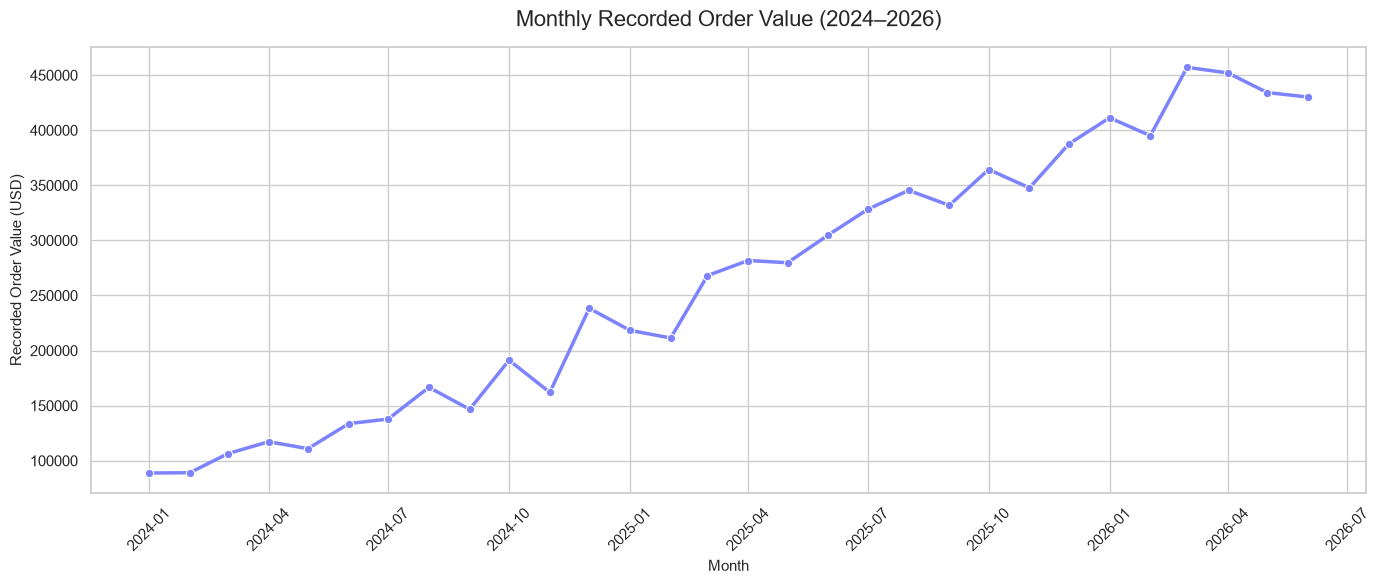

In [5]:
# Monthly recorded order value
monthly_sales = (
    orders.groupby("order_month")["order_total_usd"]
    .sum()
    .reset_index()
)

monthly_sales["order_month"] = pd.to_datetime(monthly_sales["order_month"])
monthly_sales = monthly_sales.sort_values("order_month")

# Create line chart
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="order_month",
    y="order_total_usd",
    marker="o",
    linewidth=2.5,
    color="#7C83FD"
)

plt.title("Monthly Recorded Order Value (2024–2026)", pad=15)
plt.xlabel("Month")
plt.ylabel("Recorded Order Value (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

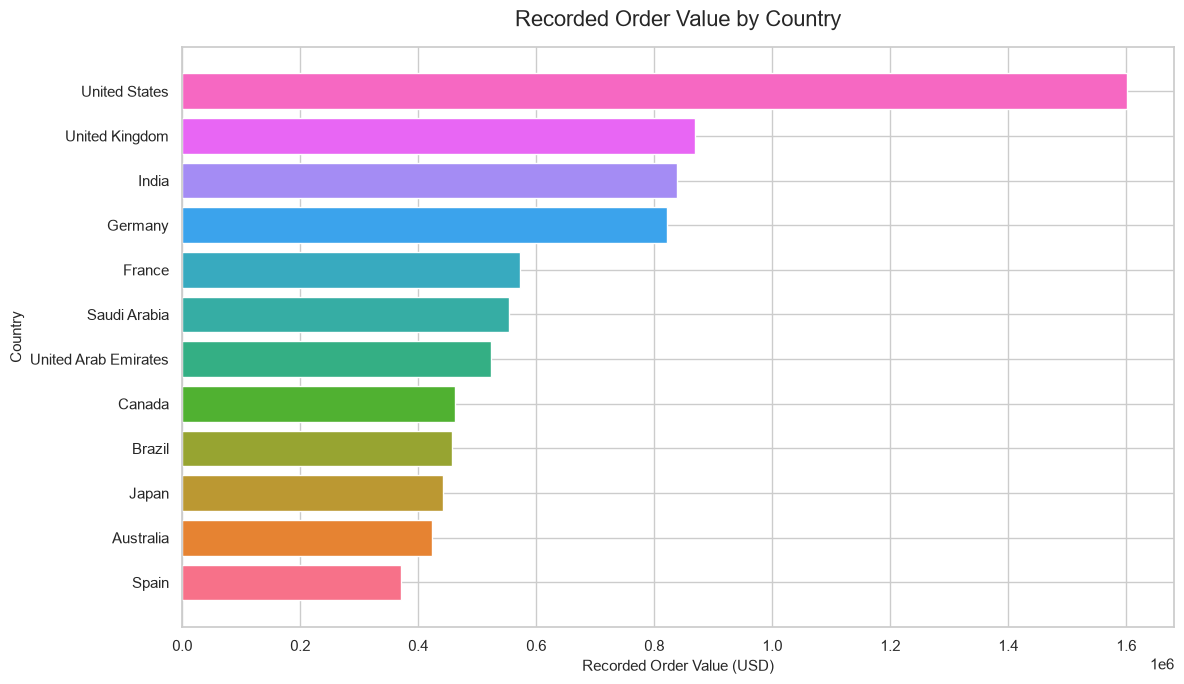

In [7]:
# Create a soft, distinct colour for each country
colors = sns.color_palette("husl", n_colors=len(country_sales))

plt.figure(figsize=(12, 7))

plt.barh(
    country_sales["shipping_country"].iloc[::-1],
    country_sales["order_total_usd"].iloc[::-1],
    color=colors
)

plt.title("Recorded Order Value by Country", pad=15)
plt.xlabel("Recorded Order Value (USD)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

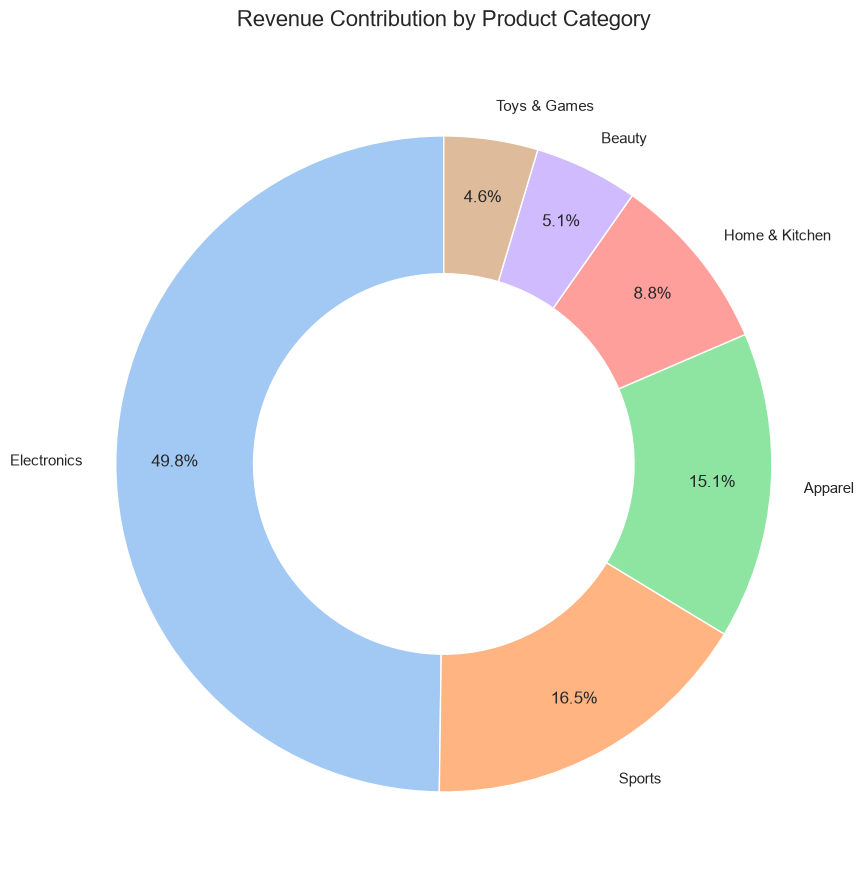

In [8]:
# Business Question: Which product categories contribute most to revenue?

category_sales = (
    order_items.merge(products, on="product_id")
    .groupby("category")["line_total_usd"]
    .sum()
    .sort_values(ascending=False)
)

colors = sns.color_palette("pastel", n_colors=len(category_sales))

plt.figure(figsize=(9, 9))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.82,
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)

plt.title("Revenue Contribution by Product Category", pad=20)
plt.tight_layout()
plt.show()

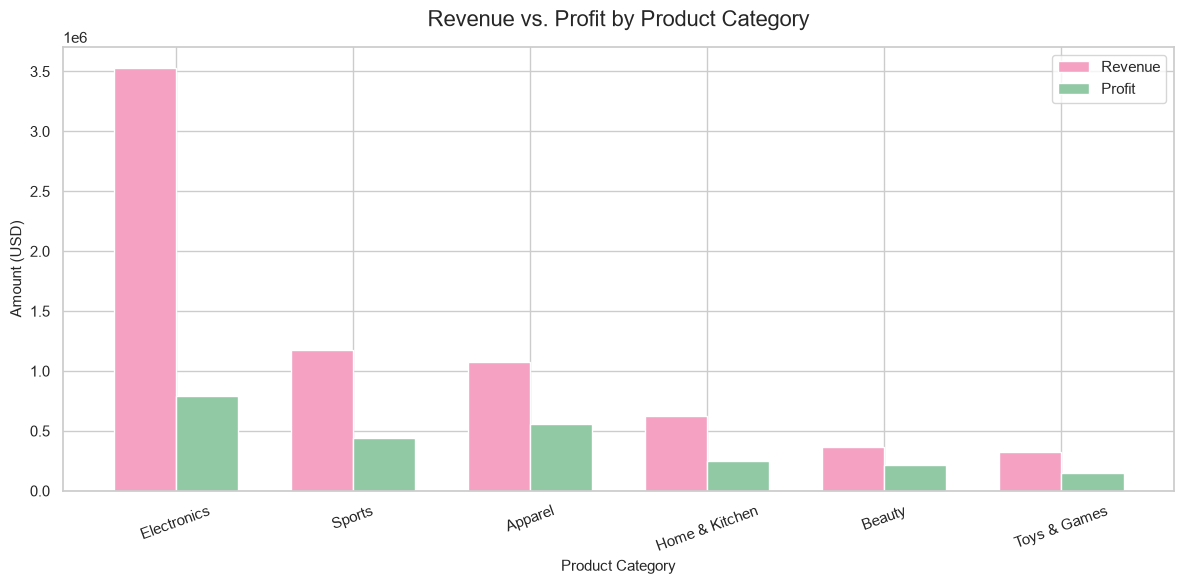

In [10]:
# Business Question: How do revenue and profit compare across product categories?

category_performance = (
    order_items.merge(products, on="product_id")
    .groupby("category")
    .agg(
        Revenue=("line_total_usd", "sum"),
        Profit=("line_profit_usd", "sum")
    )
    .reset_index()
)

category_performance = category_performance.sort_values(
    "Revenue", ascending=False
)

x = np.arange(len(category_performance))
width = 0.35

plt.figure(figsize=(12, 6))

# Revenue - Soft Pink
plt.bar(
    x - width/2,
    category_performance["Revenue"],
    width,
    label="Revenue",
    color="#F4A1C2"
)

# Profit - Soft Green
plt.bar(
    x + width/2,
    category_performance["Profit"],
    width,
    label="Profit",
    color="#91C9A5"
)

plt.title("Revenue vs. Profit by Product Category", pad=15)
plt.xlabel("Product Category")
plt.ylabel("Amount (USD)")
plt.xticks(x, category_performance["category"], rotation=20)
plt.legend()

plt.tight_layout()
plt.show()

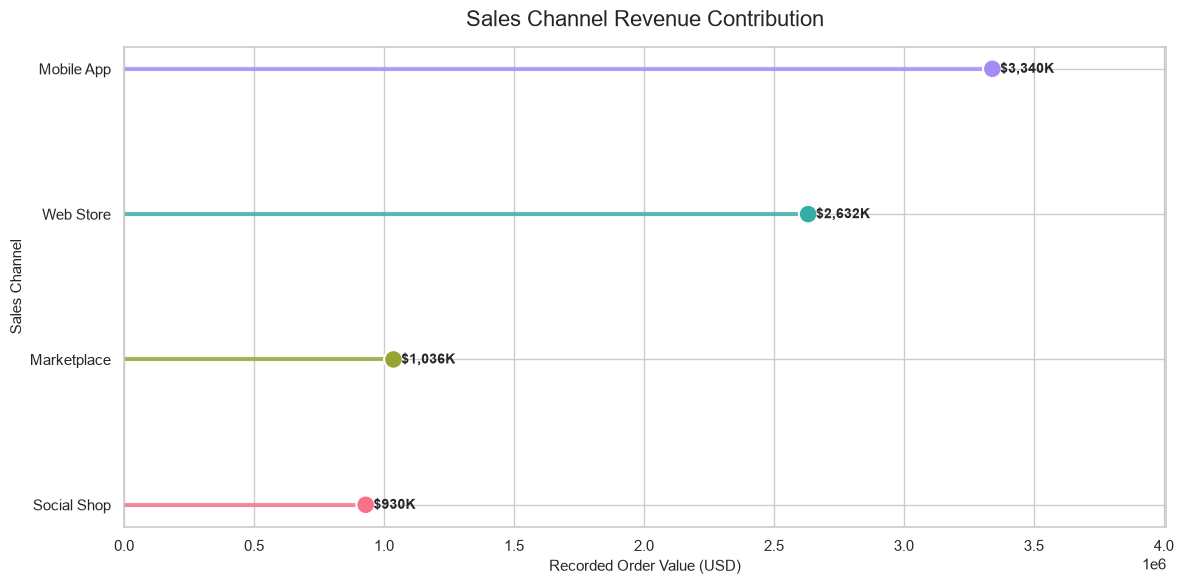

In [13]:
# Business Question: Which sales channels contribute most to recorded order value?

channel_sales = (
    orders.groupby("sales_channel")["order_total_usd"]
    .sum()
    .sort_values()
    .reset_index()
)

colors = sns.color_palette("husl", n_colors=len(channel_sales))

plt.figure(figsize=(12, 6))

plt.hlines(
    y=channel_sales["sales_channel"],
    xmin=0,
    xmax=channel_sales["order_total_usd"],
    color=colors,
    linewidth=3,
    alpha=0.8
)

plt.scatter(
    channel_sales["order_total_usd"],
    channel_sales["sales_channel"],
    color=colors,
    s=180,
    zorder=3,
    edgecolor="white",
    linewidth=1.5
)

# Add revenue data labels
for i, row in channel_sales.iterrows():
    plt.text(
        row["order_total_usd"] + 30000,
        row["sales_channel"],
        f"${row['order_total_usd']/1000:,.0f}K",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Sales Channel Revenue Contribution", pad=15)
plt.xlabel("Recorded Order Value (USD)")
plt.ylabel("Sales Channel")
plt.xlim(0, channel_sales["order_total_usd"].max() * 1.2)

plt.tight_layout()
plt.show()

In [14]:
# Business Question: Which devices do customers prefer?

device_counts = customers["preferred_device"].value_counts()

print(device_counts)

preferred_device
Mobile     1708
Desktop    1028
Tablet      264
Name: count, dtype: int64


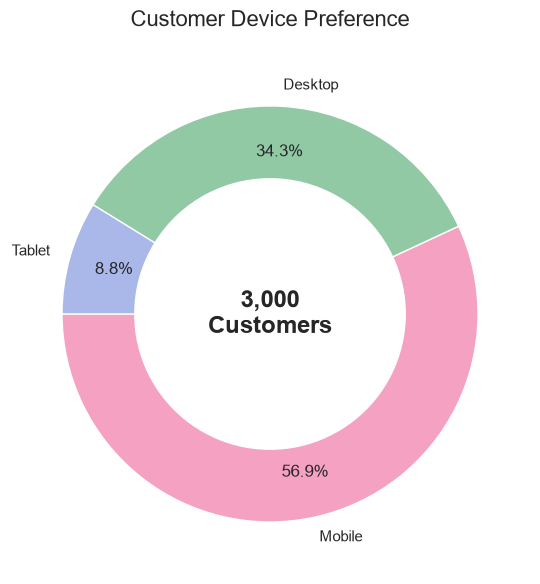

In [16]:
# Business Question: Which devices do customers prefer?

device_counts = customers["preferred_device"].value_counts()

colors = ["#F4A1C2", "#91C9A5", "#A9B8E8"]

fig, ax = plt.subplots(figsize=(9, 6))

wedges, texts, autotexts = ax.pie(
    device_counts,
    labels=device_counts.index,
    autopct="%1.1f%%",
    startangle=180,
    colors=colors,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.35,
        "edgecolor": "white"
    }
)

ax.text(
    0, 0, "3,000\nCustomers",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

plt.title("Customer Device Preference", pad=20)
plt.tight_layout()
plt.show()

In [17]:
# Business Question: What are the most common reasons for product returns?

return_reasons = (
    returns["return_reason"]
    .value_counts()
    .sort_values(ascending=True)
)

print(return_reasons)

return_reason
Late delivery                204
Quality below expectation    302
Damaged on arrival           312
Changed mind                 409
Not as described             487
Wrong size or fit            719
Name: count, dtype: int64


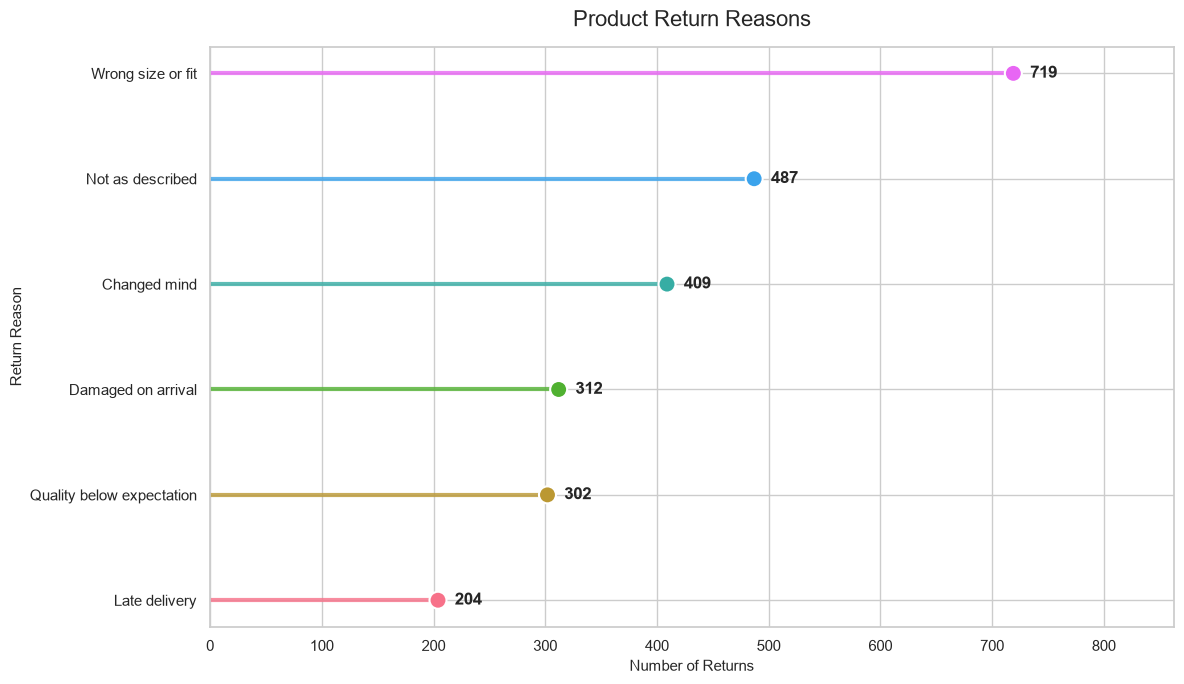

In [18]:
# Business Question: What are the most common reasons for product returns?

return_reasons = (
    returns["return_reason"]
    .value_counts()
    .sort_values()
    .reset_index()
)

return_reasons.columns = ["Return Reason", "Return Count"]

colors = sns.color_palette("husl", n_colors=len(return_reasons))

plt.figure(figsize=(12, 7))

plt.hlines(
    y=return_reasons["Return Reason"],
    xmin=0,
    xmax=return_reasons["Return Count"],
    color=colors,
    linewidth=3,
    alpha=0.8
)

plt.scatter(
    return_reasons["Return Count"],
    return_reasons["Return Reason"],
    color=colors,
    s=150,
    edgecolor="white",
    linewidth=1.5,
    zorder=3
)

# Add data labels
for i, row in return_reasons.iterrows():
    plt.text(
        row["Return Count"] + 15,
        row["Return Reason"],
        f'{row["Return Count"]:,}',
        va="center",
        fontweight="bold"
    )

plt.title("Product Return Reasons", pad=15)
plt.xlabel("Number of Returns")
plt.ylabel("Return Reason")
plt.xlim(0, return_reasons["Return Count"].max() * 1.2)

plt.tight_layout()
plt.show()

In [19]:
# Check columns needed for category return-rate analysis

print("Order Items:", order_items.columns.tolist())
print("Returns:", returns.columns.tolist())
print("Products:", products.columns.tolist())

Order Items: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price_local', 'line_discount_local', 'line_total_local', 'line_total_usd', 'unit_cost_usd', 'line_profit_usd', 'currency_code']
Returns: ['return_id', 'order_id', 'order_item_id', 'product_id', 'customer_id', 'return_date', 'return_month', 'days_to_return', 'quantity_returned', 'return_reason', 'item_condition', 'refund_amount_local', 'refund_amount_usd', 'restocked', 'currency_code']
Products: ['product_id', 'product_name', 'category', 'subcategory', 'brand', 'list_price_usd', 'unit_cost_usd', 'weight_kg', 'launch_date', 'is_active']


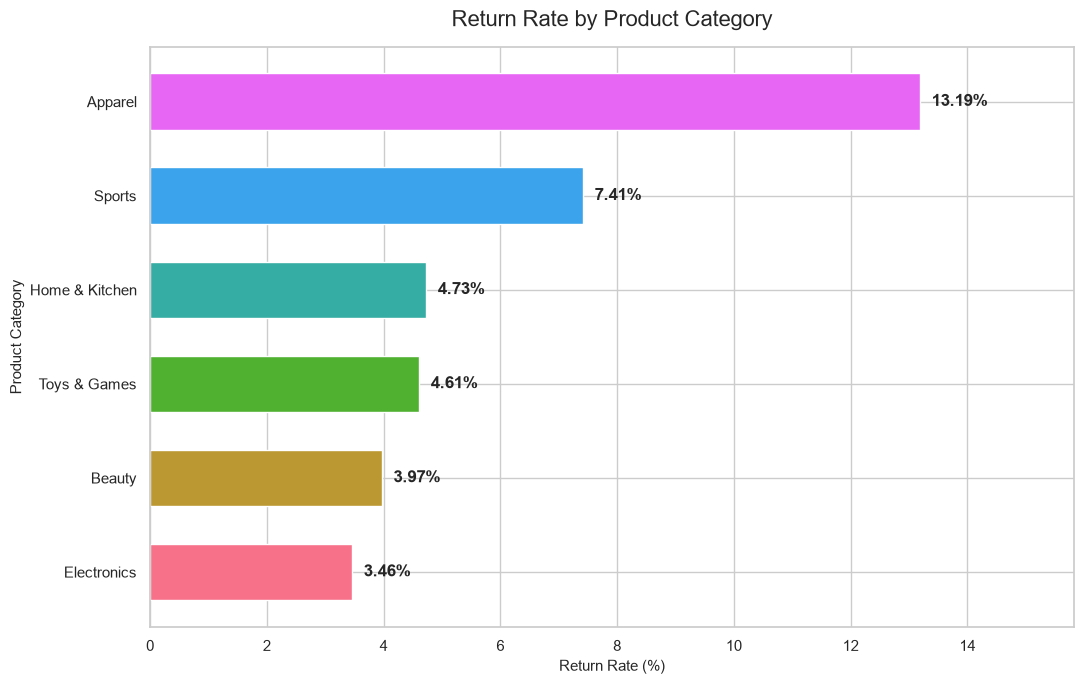

In [20]:
# Business Question: Which product categories have the highest return rates?

# Total quantity sold by category
category_sold = (
    order_items.merge(products[["product_id", "category"]], on="product_id")
    .groupby("category")["quantity"]
    .sum()
)

# Total quantity returned by category
category_returned = (
    returns.merge(products[["product_id", "category"]], on="product_id")
    .groupby("category")["quantity_returned"]
    .sum()
)

# Calculate return rate
category_return_rate = (
    category_returned / category_sold * 100
).sort_values()

# Create chart
colors = sns.color_palette("husl", n_colors=len(category_return_rate))

plt.figure(figsize=(11, 7))

bars = plt.barh(
    category_return_rate.index,
    category_return_rate.values,
    color=colors,
    height=0.6
)

# Add percentage labels
for bar, value in zip(bars, category_return_rate.values):
    plt.text(
        value + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontweight="bold"
    )

plt.title("Return Rate by Product Category", pad=15)
plt.xlabel("Return Rate (%)")
plt.ylabel("Product Category")
plt.xlim(0, category_return_rate.max() * 1.2)

plt.tight_layout()
plt.show()

## Visualization Summary

This notebook presents eight visual analyses covering:

1. Monthly recorded order value trends
2. Country-level sales performance
3. Revenue contribution by product category
4. Revenue and profit comparison
5. Sales channel contribution
6. Customer device preferences
7. Product return reasons
8. Return rates by product category

### Key Findings

- Recorded order value shows an overall upward trend.
- The United States contributes the highest recorded order value.
- Electronics accounts for the largest share of item revenue.
- Mobile App is the leading sales channel.
- Mobile is the most preferred customer device.
- Wrong size or fit is the leading return reason.
- Apparel has the highest category-level return rate.

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn